In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from neuralsde.latent_sde.model import NeuralLatentSDE

In [3]:
device = 'cpu'

In [4]:
model = NeuralLatentSDE(
    solver_dt=0.01,
    observation_std=0.1,
    initial_prior_std=0.1,
).to(device)

In [5]:
model.load_state_dict(
    torch.load('./artifacts/nsde/latent_neural_sde.pt', weights_only=True, map_location=device)['model_state']
)

<All keys matched successfully>

In [6]:
model.posterior_drift = None
model.encoder = None
model.initial_posterior = None
model.eval()

NeuralLatentSDE(
  (encoder): None
  (initial_posterior): None
  (drift): DriftNetwork(
    (network): Sequential(
      (0): Linear(in_features=2, out_features=48, bias=True)
      (1): SiLU()
      (2): Linear(in_features=48, out_features=48, bias=True)
      (3): SiLU()
      (4): Linear(in_features=48, out_features=1, bias=True)
    )
  )
  (diffusion): DiffusionNetwork(
    (network): Sequential(
      (0): Linear(in_features=2, out_features=48, bias=True)
      (1): SiLU()
      (2): Linear(in_features=48, out_features=48, bias=True)
      (3): SiLU()
      (4): Linear(in_features=48, out_features=1, bias=True)
    )
  )
  (posterior_drift): None
  (decoder): DecoderNetwork(
    (network): Sequential(
      (0): Linear(in_features=1, out_features=48, bias=True)
      (1): Tanh()
      (2): Linear(in_features=48, out_features=48, bias=True)
      (3): Tanh()
      (4): Linear(in_features=48, out_features=1, bias=True)
    )
  )
)

In [7]:
times = torch.load('./artifacts/nsde/data.pt')['shared_time_grid']

The latent state $Z_t$ evolves according to the stochastic differential equation
$$
dZ_t = f_\theta(t,Z_t)\,dt + g_\theta(t,Z_t)\,dW_t.
$$

The decoder maps it to the observed process
$$X_t=h_\theta(Z_t)$$

The `sample` function integrates the latent SDE first and then decodes the resulting paths. Different Brownian motion realizations produce different trajectories, even when the initial state is the same.

In [8]:
def sample(model: NeuralLatentSDE, times, n=10):
    generator=torch.Generator(device).manual_seed(42)
    latent = model._integrate(n, times, generator=generator, initial_state=torch.zeros((n, 1))).paths
    return model.decode(latent).detach().cpu()[:,:,0].T

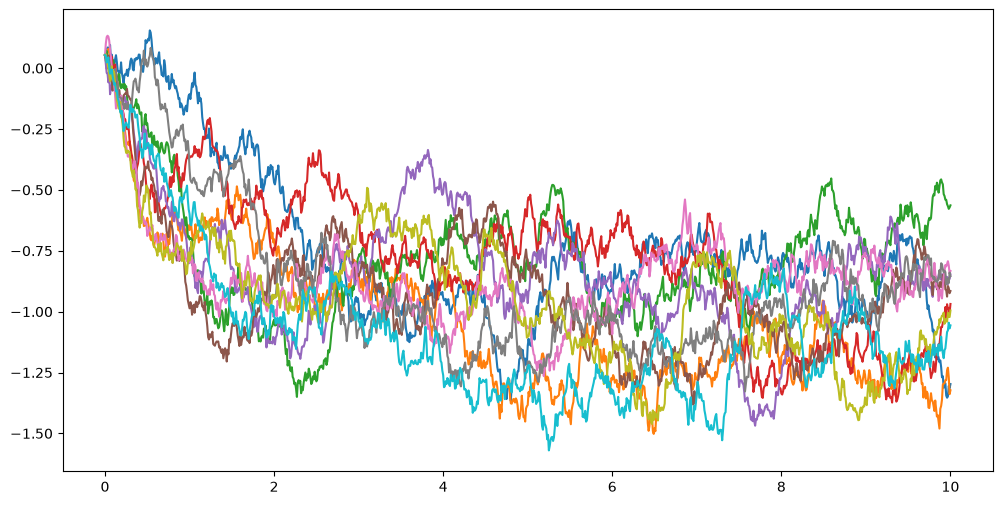

In [9]:
plt.figure(figsize=(12, 6))
plt.plot(times, sample(model, times));

In [10]:
class ZeroDiffusion(nn.Module):
    def forward(self, time: torch.Tensor, state: torch.Tensor) -> torch.Tensor:
        return torch.zeros(time.shape[0], 1, device=time.device, dtype=time.dtype)

def sample_drifts():
    model0 = NeuralLatentSDE(
        solver_dt=0.01,
        observation_std=0.1,
        initial_prior_std=0.1,
    ).to(device)

    model0.load_state_dict(model.state_dict(), strict=False)
    model0.diffusion = ZeroDiffusion()

    samples = []

    ddt = 5
    for t0 in range(0, int(10*ddt)):
        t0 /= ddt
        times = torch.linspace(t0, 10, steps=int((10-t0)/0.01))
        path = sample(model0, times, n=1)
        samples.append((times, path))

    return samples

In [11]:
import numpy as np

def validate_grid(x_grid):
    # A single-valued field in X requires a one-to-one decoder on the sampled interval.
    dx = np.diff(x_grid)
    if not np.all(np.isfinite(x_grid)):
        raise ValueError('Decoder returned non-finite X-grid coordinates.')
    if not (np.all(dx > 0) or np.all(dx < 0)):
        raise ValueError('Decoder is not strictly monotone over the chosen latent interval; '
                         'a single-valued drift/diffusion field in X cannot be plotted.')

Let $X_t=h_\theta(Z_t)$ with latent dynamics $dZ_t=f_\theta(t,Z_t)\,dt+g_\theta(t,Z_t)\,dW_t$. Itô's formula yields

$$
\mu_X(t,x)=h_\theta'(z)f_\theta(t,z)+\tfrac12h_\theta''(z)g_\theta(t,z)^2,
\qquad z=h_\theta^{-1}(x).
$$

Here we plot the transformed drift against the observed coordinate $x$. We first choose a uniform latent grid $z_i$, then use the observed grid $x_i=h_\theta(z_i)$.

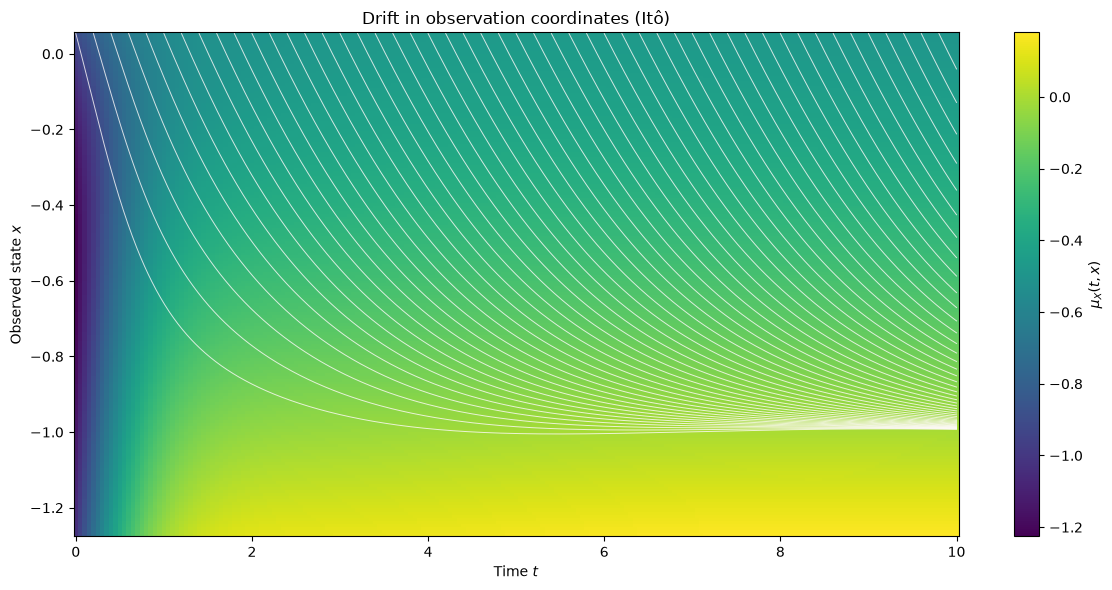

In [ ]:
# Start with a uniform latent grid, then map it into observation coordinates.
# The resulting x_grid is generally nonuniform.
times = torch.linspace(0, 10, 201, device=device)
states = torch.linspace(-1.75, 0.0, 181, device=device)

with torch.no_grad():
    x_grid = model.decoder(states[:, None]).reshape(-1).detach().cpu().numpy()
    validate_grid(x_grid)

T, Z = torch.meshgrid(times, states, indexing="xy")
t = T.reshape(-1, 1)
z = Z.reshape(-1, 1).detach().requires_grad_(True)

f = model.drift(t, z)
g = model.diffusion(t, z)
x = model.decoder(z)
dx_dz = torch.autograd.grad(x.sum(), z, create_graph=True)[0]
d2x_dz2 = torch.autograd.grad(dx_dz.sum(), z)[0]

# Ito drift on the latent grid, plotted at x = h(z).
drift_x = (dx_dz * f + 0.5 * d2x_dz2 * g.square())
drift_x = drift_x.reshape(len(states), len(times)).detach().cpu().numpy()

# pcolormesh accepts unevenly spaced x values directly; no regridding.
# If the decoder is decreasing, pcolormesh still draws the cells correctly.
fig, ax = plt.subplots(figsize=(12, 6))
mesh = ax.pcolormesh(times.detach().cpu().numpy(), x_grid, drift_x,
                     shading='auto', cmap='viridis')
fig.colorbar(mesh, ax=ax, label=r'$\mu_X(t,x)$')

sampled = sample_drifts()
for time, path in sampled:
    sns.lineplot(x=time, y=path[:, 0], color="snow", linewidth=0.7, alpha=0.8, ax=ax)

ax.set_xlabel('Time $t$')
ax.set_ylabel('Observed state $x$')
ax.set_title('Drift in observation coordinates (Itô)')

plt.tight_layout()
plt.show()

The transformed diffusion is
$$
\sigma_X(t,x)=h_\theta'(z)g_\theta(t,z),\qquad z=h_\theta^{-1}(x).
$$

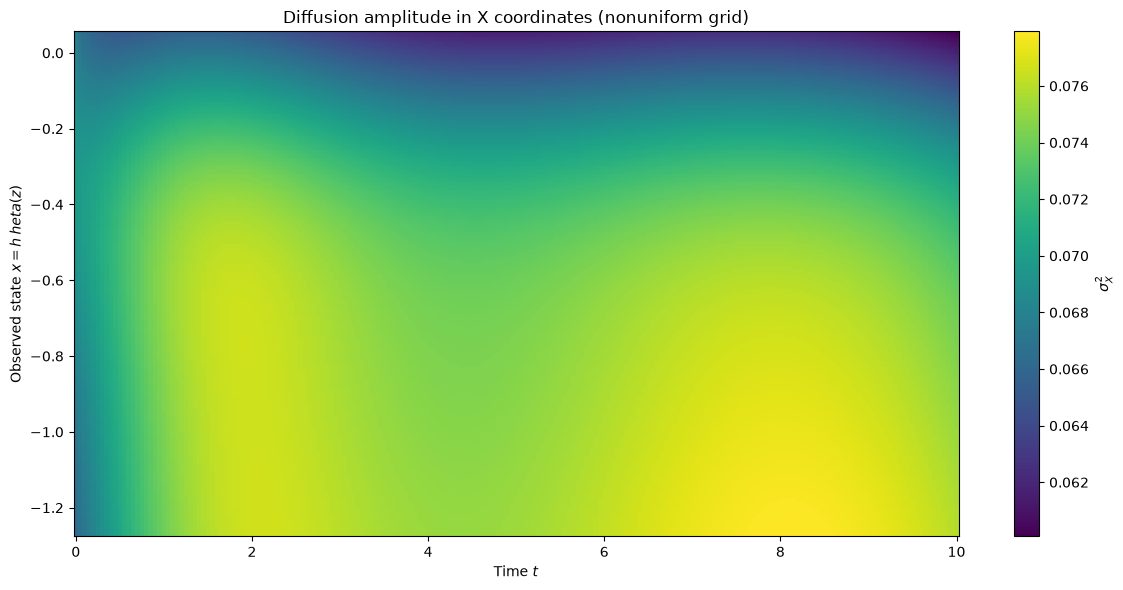

In [13]:
latent_diffusion = model.diffusion(t, z)
decoded = model.decoder(z)
h_prime = torch.autograd.grad(decoded.sum(), z)[0]

sigma_x = h_prime * latent_diffusion
diffusion_x = sigma_x.square().reshape(len(states), len(times)).detach().cpu().numpy()

fig, ax = plt.subplots(figsize=(12, 6))

mesh = ax.pcolormesh(
    times.detach().cpu().numpy(),
    x_grid,
    diffusion_x,
    shading="auto",
    cmap="viridis",
)

fig.colorbar(mesh, ax=ax, label=r"$\sigma_X^2$")

ax.set_xlabel("Time $t$")
ax.set_ylabel("Observed state $x = h_\theta(z)$")
ax.set_title("Diffusion amplitude in X coordinates (nonuniform grid)")

plt.tight_layout()
plt.show()